# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Grupo 4

# Integrantes
* Tomas Mateos
* Martin Mateos
* Maximo Ubalari
* Juan Manuel Alsina

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.


#### _Respuesta inciso a_.
##### ¿Cual es el rango de $Q\in \mathbb{R}^{2n \times 12}$ para que la solución sea no nula única a menos de un factor de escala?
Para obtener una solución no nula $\text{dim}(\text{Nu}(Q)) \geq 1$ y para que sea a un factor de escala entonces $\text{Nu}(Q) = 1$, si $Q$ es la matriz de una transformación lineal $T$ entonces $T: \mathbb{V} \to \mathbb{W}$ donde $\mathbb{V} = \mathbb{R}^{12}$ y $\text{Im}(T) \subset \mathbb{R}^{2n}$. Por el teorema de la dimensión: $\text{dim}(\text{Im}(Q))+ \text{dim}(\text{Nu}(Q)) = \text{dim}(\text{Im}(Q)) + 1 = 12 \iff \text{dim}(\text{Im}(Q)) = 11$. Por lo tanto, como $\text{dim}(\text{Im}(Q)) = \text{rg}(Q)$, se tiene que el rango de $Q$ es igual a 11.
##### ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?
Teniendo en cuenta que cada punto aporta dos ecuaciones lineales independientes por $\mathbb{V} = \mathbb{R}^{2n}$ con $n \in \mathbb{N}$ como el número de puntos y que $2n \geq \text{rg}(Q)$, entonces $2n \geq 11 \implies n=6$. Por lo tanto, el número mínimo de puntos necesarios que aseguran la solución son 6.
La condición que deben cumplir es que los 6 puntos deben ser no coplanares entre sí y además una de las 12 filas de $Q$ debe ser combinación lineal de las otras 11 porque si $\text{rg}(Q)=12 \implies \text{Nu}(Q) = 0 \implies m = \vec{0}$, luego la matriz $M$ es nula. Si $\text{rg}(Q) \leq 10$ entonces $\text{Nu}(Q) \geq 2 $ provocando infinitas soluciones. Por ejemplo, si $\text{Nu}(Q) \geq 2 $ entonces existen al menos $m_1, m_2$ con matrices asociadas $M_1=\lambda_1 m_1$, $ M_2=\lambda_2 m_2$ luego $M = Qm = Q(\lambda_1 m_1 + \lambda_2 m_2)$ existiendo así infinitos valores intrínsecos y extrínsecos.
En conclusión 11 de las 12 filas de $Q$ son linealmente independientes y **los 6 puntos deben ser no coplanares**, pues en caso contrario, disminuiría el rango de la matriz y en consucuencia aumentando la dimensión de su núcleo obteniendo así infinitas soluciones.

#### _Respuesta inciso b_.
En teoría deberíamos hallar la solucion del sistema $Qm = 0$ donde $rg(Q) = 11$. Pero en la práctica, generalmente los errores podrían provocar que $rg(Q) = 12$, obteniendo la solución trivial y la matriz $M$ resultaría nula. Para evitar obtener la solución trivial se busca resolver el problema de mínimos cuadrados homogéneos con restricción de norma.
Toda matriz rectangular posee descomposición en valores singulares por lo que $Q = U \Sigma V^t$. Como $U$ es unitaria se tiene que:
$$
\begin{aligned}
||Qm||_2^2 &= ||U \Sigma V^t m||_2^2 \\
&=  ||U (\Sigma V^t m)||_2^2 \\
&= ||\Sigma V^t m||_2^2
\end{aligned}
$$
Entonces $||Qm||_2 ^2 = ||\Sigma V^t m||_2 ^2$.
Como $V$ es unitaria, tomando como vectores sus columnas, estos forman una base ortonormal de $\mathbb{R}^{12}$ de modo que $m = \sum_{i=1}^{12}\alpha_i v_i$ con $\sum_{i=1}^{12}\alpha_i^2 = 1$. Sea $A = (\alpha_1, \alpha_2, ... , \alpha_{12}) \in \mathbb{R}^{12}$, de forma matricial $m = VA$, luego
$$
\begin{aligned}
\Sigma V^t m &= \Sigma V^t VA \\
&= \Sigma (V^t V)A \\
&= \Sigma A
\end{aligned}
$$
De esta manera,
$$
\begin{aligned}
||Qm||_2 ^2 &= ||\Sigma A||_2 ^2 \\
&= \sum_{i=1}^{12} \sigma_i^2 \alpha_i^2 \\
&\geq \sigma_{12}^2 \sum_{i=1}^{12} \alpha_i^2 = \sigma_{12}^2
\end{aligned}
$$
El valor mínimo de la norma es $\sigma_{12}^{2}$. Este mínimo se alcanza cuando $A=\pm(0, 0, ... , 1)$ y por lo tanto $m = \pm v_{12}$.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$



## Descripción de los Datasets.
### `detected_corners.txt`
El archivo contiene una tabla de `float` separados por espacios de dimensión $(210 \times 24)$.

Cada fila representa una imagen que contiene las coordenadas 2D de 12 puntos detectados. Las columnas están agrupadas en pares $(u_1, v_1), (u_2, v_2), \dots, (u_12, v_12)$.

### `p_W_corners.txt`
Contiene una tabla de `float` separados por comas ',' de dimension $(12 \times 3)$.

Cada i-ésima fila contiene las coordenadas 3D asociadas a la i-ésima coordenada 2D de una imagen cualquiera en `detected_corners.txt`.

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/tp ALC/')
import alc as alc
import numpy as np
# importamos los modulos.

In [3]:
np.set_printoptions(precision=8, suppress=True, linewidth=200) # Para facilitar legibilidad.
ruta = 'calib/3d/'
fotos = np.loadtxt(ruta + 'detected_corners.txt') # pixels (2D)
pcorners = np.loadtxt(ruta + 'p_W_corners.txt',delimiter=',') # dimensiones 3D

fotos.shape

(210, 24)

In [4]:
objPts = alc.convertirP(pcorners)
uvp = alc.puntosfotoi(20,fotos)
Q = alc.obtenerQ3d(uvp, objPts)

## Obtencion de $M$, $K$ y $t$
Para obtener la descomposicion de R, puedo utilizar la descomposicion RQ que sale de hacer la inversa de su QR.
Para ello necesito las funciones calculaQR y la inversa, (mi inversa usa la descomposicion LU de la matriz).
$M = [A|b]$ donde $M = [KR|KT]$, $A = KR$ y $b = Kt$.

Separando `M[:,0:3] = A` y `M[:,3] = b`

In [5]:
M = alc.resolverDLT3D(Q)
A = M[:,0:3].copy()
b = M[:,3].copy()
# Como quiero sacar RQ en vez de QR calculo la inversa de A y luego la descomp QR me termina quedando KR
Ainv = alc.inversa(A)
Qinv, Rinv = alc.QR_con_HH(Ainv)
K = alc.inversa(Rinv)
R = Qinv.T

# K[2,2] es el factor de escala, debo dividir a b y K por este valor
Knormalizada = K / K[2, 2]

print(Knormalizada)

[[424.78673272  -0.33494153 356.59082288]
 [  0.         421.68914522 251.66979872]
 [  0.           0.           1.        ]]


In [6]:
# Como b = Kt entonces t = Kinv * B
t = alc.multMat(alc.inversa(K),b.reshape(-1,1))
t = t.flatten() # es lo mismo que reshape(1,-1)
# no uso la Knormalizada pues si ponele que esta escalada por un valor lambdea, entonces mi K sin normalizar seria mas un lambdaK, y cuando hago la inversa me queda 1/lambda * Kinv. entonces al multiplicar por por lambdab ya estaria normalizando
# De la DLT obtenemos la matriz con una escala global lambda

print(t)

[ 16.62193462  13.13079617 -41.37376529]


In [7]:
M = alc.resolverDLT3D(Q)
R,t,K = alc.devolverMatricesCalibracion3d(M,k12igual0=True,uigualv=True)
print(R)
print('----------------------------------------')
print(t)
print('----------------------------------------')
print(K)

[[-0.62544069 -0.11943169  0.77107718]
 [ 0.3217228  -0.93977556  0.11539642]
 [-0.7108575  -0.32024673 -0.62619777]]
----------------------------------------
[[ 16.62193461  13.13079617 -41.37376529]]
----------------------------------------
[[424.7867327    0.         356.59082285]
 [  0.         424.7867327  251.66979875]
 [  0.           0.           1.        ]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

### ¿Cuál es el rango de $Q \in \mathbb{R}^{2n \times 9}$ para asegurar una solución única a menos de un factor de escala?

Para obtener una solución no nula entonces $\text{dim}(\text{Nu}(Q)) \geq 1$ y para que sea a un factor de escala entonces $\text{Nu}(Q) = 1$, si $Q$ es la matriz de una transformación lineal $T: \mathbb{V} \to \mathbb{W}$ donde $\mathbb{V} = \mathbb{R}^{9}$ y $\text{Im}(T) \subset \mathbb{R}^{2n}$. Por el teorema de la dimensión: $\text{dim}(\text{Im}(Q))+ \text{dim}(\text{Nu}(Q)) = \text{dim}(\text{Im}(Q)) + 1 = 9 \iff \text{dim}(\text{Im}(Q)) = 8$. Por lo tanto, como $\text{dim}(\text{Im}(Q)) = \text{rg}(Q)$, se tiene que el rango de $Q$ es igual a 8.

In [8]:
# primero tema con los datos
import cv2
def formarpuntos():
    # Dimensiones de las esquinas internas indicadas en el enunciado
  filas = 7  # j = 0, ..., 6
  columnas = 11  # i = 0, ..., 10
  tam_cuadrado = 30  # 30 mm
  # tenemos 7*11 esquinas totales, y 3 cordenadas espaciales, X Y Z pero quiero que Z sea 0 pues es en un plano. para hacerlo 2d
  objp = np.zeros((7*11,3)) # creo mis puntos donde voy a guardar las esquinas, y mi punto 3d
  idx = 0
  for i in range(0,filas):
    for j in range(0,columnas):
      objp[idx,0] = j * tam_cuadrado# Eje X
      objp[idx,1] = i * tam_cuadrado# Eje Y
      objp[idx,2] = 1 # osea pues mi Z es 0 siempre para el plano, pero como luego lo necesito a 1 para Q, lo dejo en 1 y me ahorro cuentas
      # Porque las columnas son mi X y mi filas son mi Y, bueno si miramos como se mueven en las matrices tiene sentido las filas van de arriba a abajo y las columnas de izquierda a derecha.
      idx+=1 # esto va a llegar hasta el final tipo 77
  rutas_imagenes = []
  nfotos = 11 # fotos disponibles + 1 aca usamos 11 pq al principio habia solo 10 fotos
  for i in range(1,nfotos):
    rutas_imagenes.append(f'calib/coplanar/Im_R_{i}.png') # Iteramos todas las rutas de las fotos
  rutas_imagenes
  puntos3D = []
  puntos2D = []

  for ruta in rutas_imagenes:
    img = cv2.imread(ruta) # Leo las rutas, osea leo cada imagen
    imgGray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) # esto convierte a escala de grises los datos pues findChessboardCorners usa escala de grises no puedo meter a color

    encontrado, corners = cv2.findChessboardCorners(imgGray , (columnas,filas), None) # (imagenGrises,(7,11) flags= None osea por defecto todo)
    # devuelve si encontro o no con True o False, y en corners me devuelve mis u,v que necesito para los puntos.
    if encontrado == True:
      # Si tengo el punto encontrado, lo combino con mi punto de objp
      puntos3D.append(objp)
      puntos2D.append(corners)
      print(f"Tablero detectado correctamente en: {ruta}")
    else:
      print(f"No se pudo detectar el tablero en {ruta}")
  # Me termina quedando dos listas de 10 elementos
  # donde cada elemento es una lista de 77 filas y 3 y 2 columnas respectivamente para 3d y 2d
  return puntos2D,puntos3D


In [9]:
puntos2D,puntos3D = formarpuntos()

Tablero detectado correctamente en: calib/coplanar/Im_R_1.png
Tablero detectado correctamente en: calib/coplanar/Im_R_2.png
Tablero detectado correctamente en: calib/coplanar/Im_R_3.png
Tablero detectado correctamente en: calib/coplanar/Im_R_4.png
Tablero detectado correctamente en: calib/coplanar/Im_R_5.png
Tablero detectado correctamente en: calib/coplanar/Im_R_6.png
Tablero detectado correctamente en: calib/coplanar/Im_R_7.png
Tablero detectado correctamente en: calib/coplanar/Im_R_8.png
Tablero detectado correctamente en: calib/coplanar/Im_R_9.png
Tablero detectado correctamente en: calib/coplanar/Im_R_10.png


In [10]:
# puntos 2D y 3D son una lista de longitud igual a la cantidad de fotos, cada elemento de la lista es una matriz de 77x2 y 77x3 respectivamente. pues 2D y 3D
print(puntos2D[0].shape)
print(puntos3D[0].shape)

(77, 1, 2)
(77, 3)


In [11]:
# Probamos con la primera imagen para generar su Q
puntos2DLimpios = []
for i in range(0, len(puntos2D)):
    puntos2DLimpios.append(np.array(puntos2D[i]).reshape(-1,2))
puntos2D = np.array(puntos2DLimpios)
Q = alc.obtenerQ2d(puntos2DLimpios[0], puntos3D[0])

import sys # para ver Q entera
np.set_printoptions(precision=2, suppress=True, linewidth=200, threshold=sys.maxsize)

print(Q)

[[      0.         0.         1.         0.         0.         0.        -0.        -0.      -372.63]
 [      0.         0.         0.         0.         0.         1.        -0.        -0.      -104.17]
 [     30.         0.         1.         0.         0.         0.    -12407.05      -0.      -413.57]
 [      0.         0.         0.        30.         0.         1.     -3154.68      -0.      -105.16]
 [     60.         0.         1.         0.         0.         0.    -27239.27      -0.      -453.99]
 [      0.         0.         0.        60.         0.         1.     -6345.98      -0.      -105.77]
 [     90.         0.         1.         0.         0.         0.    -44509.12      -0.      -494.55]
 [      0.         0.         0.        90.         0.         1.     -9608.02      -0.      -106.76]
 [    120.         0.         1.         0.         0.         0.    -64187.34      -0.      -534.89]
 [      0.         0.         0.       120.         0.         1.    -12896.45    

In [12]:
def armarHlst(puntos2D,puntos3D): # Las H se obtienen de la misma forma que M en punto 2, el vector asociado al menor valor singular y luego le hago un reshape a matriz. Uso SVD
  n = len(puntos2D) # este n es igual a la cantidad de fotos ambos puntos2d y 3d tienen len = 10 pues es la cantidad de fotos que me dieron.
  Hlst = []
  for i in range(0,n):
    p2d = puntos2D[i].reshape(-1,2).copy() # cv2 me deja puntos2D[i] con shape(77,1,2) entonces tengo que hacer un reshape para que quede en (77,2)
    p3d = puntos3D[i] # Como hice la lista de puntos 3D a mano tiene el problema que tiene puntos 2D osea que ya tengo mi (77,3)
    Q = alc.obtenerQ2d(p2d,p3d) # Obtenemos Q para los puntos
    H = alc.resolverQh(Q) # resolvemos con SVD el vector h que minimiza... la funcion ya me lo devuelve en forma de matriz
    if abs(H[2, 2]) > 1e-12: # normalizamos H para no tener problemas mas adelante
      H = H / H[2, 2]
    Hlst.append(H) # lo metemos a la lista
  return Hlst
Hlst = armarHlst(puntos2D,puntos3D)

In [13]:
A = alc.armarA(Hlst)
A

array([[-0.04,  1.89,  0.04, -0.  ,  0.  , -0.  ],
       [ 1.9 ,  0.16, -1.87,  0.  ,  0.  ,  0.  ],
       [ 0.41,  1.72, -0.39,  0.  ,  0.  , -0.  ],
       [ 1.72, -1.61, -1.71,  0.  , -0.  ,  0.  ],
       [ 0.12,  1.99, -0.08,  0.  ,  0.  ,  0.  ],
       [ 2.01, -0.4 , -1.97,  0.  , -0.  ,  0.  ],
       [ 0.1 ,  2.07, -0.01,  0.  ,  0.  ,  0.  ],
       [ 2.05, -0.22, -2.09,  0.  , -0.  , -0.  ],
       [-0.17,  2.02,  0.19, -0.  ,  0.  , -0.  ],
       [ 2.11,  0.72, -1.93,  0.  ,  0.  ,  0.  ],
       [-0.05,  2.04,  0.09, -0.  ,  0.  , -0.  ],
       [ 2.11,  0.3 , -1.97,  0.  ,  0.  ,  0.  ],
       [ 0.15,  2.04, -0.06,  0.  ,  0.  ,  0.  ],
       [ 2.  , -0.42, -2.08,  0.  , -0.  , -0.  ],
       [ 0.16,  2.24, -0.06, -0.  ,  0.  , -0.  ],
       [ 2.38, -0.43, -2.1 ,  0.  ,  0.  ,  0.  ],
       [ 0.56,  2.04, -0.38,  0.  ,  0.  ,  0.  ],
       [ 1.91, -1.89, -2.16, -0.  , -0.  , -0.  ],
       [-0.08,  1.82, -0.09, -0.  ,  0.  , -0.  ],
       [ 1.98, -0.05, -1.66,  0

In [14]:
K = alc.calcularMatrizK2D(A)
K

array([[746.47,  -0.67, 520.71],
       [  0.  , 757.78, 298.59],
       [  0.  ,   0.  ,   1.  ]])

In [15]:
# La pose de la camara para cada foto se da por la matriz de rotacion y el vector de traslacion.
# Seleccionamos la foto que queremos pasandole el valor de Hlst y nuestra K.
fotonumeroi = 0 # Si queremos la pose de la foto 1, ponemos 0 la pose de la foto 10, ponemos 9  y asi.
R,t = alc.obtenerPose2D(Hlst[fotonumeroi],K)
print(R)
print(t)

[[ 1.   -0.01 -0.03]
 [ 0.01  1.    0.01]
 [ 0.03 -0.01  1.  ]]
[[-109.45]
 [-141.36]
 [ 551.28]]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [16]:
import matplotlib.pyplot as plt
import cv2

#puntos (u, v) de los jugadores argentinos en la imagen "test-gol-enzo.png"
pies_jugadores_arg = [
    [799, 536],
    [96, 528],
    [240, 402],
    [377, 324],
    [380, 286],
    [850, 343]
]
#puntos (u,v) de la imagen "test-gol-enzo.png"
imgPts = np.array([
    [383.0, 177.0],  # palo izquierdo
    [654.0, 183.0],  # palo derecho
    [193.0, 171.0],  # linea del fondo izquierda
    [840.0, 188.0],  # linea del fondo derecha
    [862.0, 247.0],  # esquina del area chica derecha
    [155.0, 228.0],  # esquina del area chica izquierda
    [150.0, 406.0],  # medialuna izquierda
    [848.0, 420.0],  # medialuna derecha
    [512.0, 312.0]   # punto penal
], dtype=np.float32)

#puntos (u, v, 1) de la imagen "estadio_azteca.png"
objPts = np.array([
    [7.40, 33.45, 1.0],   # palo izquierdo
    [7.40, 38.63, 1.0],   # palo derecho
    [7.40, 29.98, 1.0],   # linea del fondo izquierda
    [7.40, 42.76 , 1.0],  # linea del fondo derecha
    [9.45, 42.76, 1.0],   # esquina del area chicha derecha
    [9.45, 29.48, 1.0],   # esquina del area chicha izquierda
    [13.67, 31.21, 1.0],  # medialuna izquierda
    [13.67, 41.46, 1.0],  # medialuna derecha
    [11.62, 36.26, 1.0]   # punto penal
], dtype=np.float32)

#consigo H homografia basandonos en imgPts y objPts
Q = alc.obtenerQ2d(imgPts, objPts)
H = alc.resolverQh(Q)

def punto_a(H, pies_jugador):
    u_linea_gol=0.0
    H_inv = alc.inversa(H)

    # coordenadas homogéneas de los pies en la imagen (u, v, 1)
    pies_jugador_img = np.array([pies_jugador[0], pies_jugador[1], 1.0])

    # proyectar a la cancha
    puntos_cancha_hom = alc.multMat(H_inv, pies_jugador_img)
    U_jugador = puntos_cancha_hom[0] / puntos_cancha_hom[2]
    V_jugador = puntos_cancha_hom[1] / puntos_cancha_hom[2]

    # distancia perpendicular a la línea de gol
    distancia_arco = abs(U_jugador - u_linea_gol)
    return distancia_arco, (U_jugador, V_jugador)


Para probar la funcion punto_a podemos hacer lo siguiente:

In [17]:
for pies in pies_jugadores_arg:
    distancia, (U, V) = punto_a(H, pies)
    print(f"({distancia}, ({U}, {V}))")

print(f"Homografia H:\n{H}")

([15.92], ([15.92], [40.31]))
([15.75], ([15.75], [31.2]))
([13.56], ([13.56], [32.36]))
([11.81], ([11.81], [34.03]))
([10.85], ([10.85], [33.92]))
([12.08], ([12.08], [41.87]))
Homografia H:
[[ 0.02 -0.04  1.  ]
 [-0.02 -0.    0.05]
 [ 0.   -0.   -0.  ]]


In [18]:
def punto_b(H, pos_cancha_jugador, num_puntos=100, radio=1.0):
    U_c, V_c = pos_cancha_jugador

    # circulo en coordenadas de la cancha
    thetas = np.linspace(0, 2 * np.pi, num_puntos)
    U_circulo = U_c + radio * np.cos(thetas)
    V_circulo = V_c + radio * np.sin(thetas)

    u_proyectados = []
    v_proyectados = []

    # proyecta cada punto del círculo a la imagen usando H
    for i in range(num_puntos):
        P_hom = np.array([U_circulo[i], V_circulo[i], 1.0])

        m_hom = alc.multMat(H, P_hom)

        # deshomogeneizar para obtener el píxel (u, v)
        u_img = m_hom[0] / m_hom[2]
        v_img = m_hom[1] / m_hom[2]

        u_proyectados.append(u_img)
        v_proyectados.append(v_img)

    return u_proyectados, v_proyectados

Para probar la funcion punto_b hacemos lo siguiente:

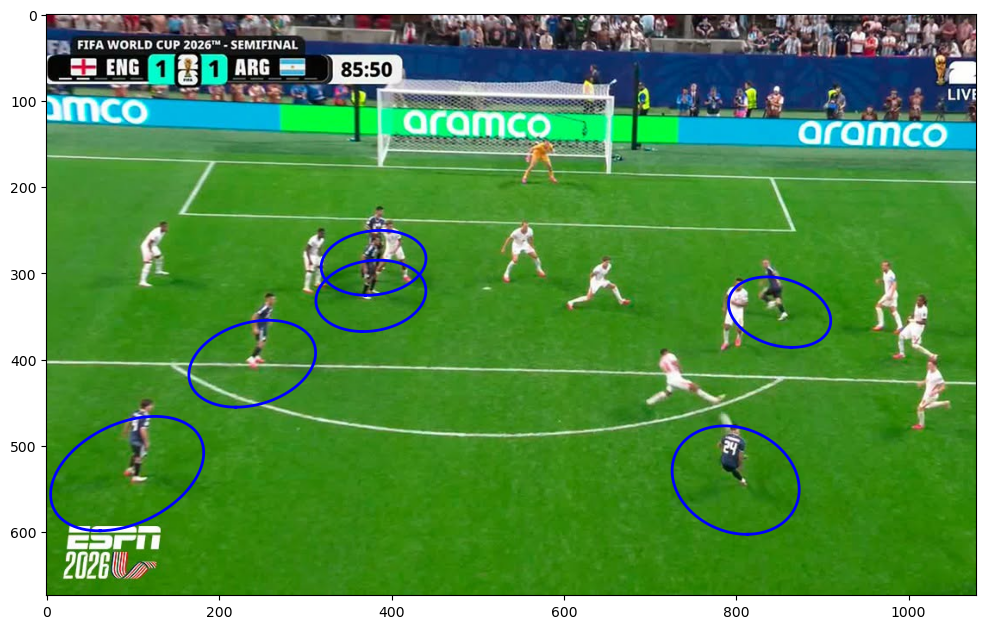

In [19]:
img_enzo_bgr = cv2.imread('futbol/test-gol-enzo.png')
img_enzo_rgb = cv2.cvtColor(img_enzo_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_enzo_rgb)

for pie in pies_jugadores_arg:
    _, pos_cancha = punto_a(H, pie)

    # marcar el ciculo en la imagen
    u_circ, v_circ = punto_b(H, pos_cancha, radio=1.0)
    plt.plot(u_circ, v_circ, color='blue', linewidth=2)
plt.show()

In [20]:
imgPts2 = np.array([
    [1234, 392],  # borde del area derecha
    [1367, 576],  # borde del area izquierda
    [740, 410],   # medialina derecha
    [740, 550],   # medialuna izquierda
    [1002, 464]   # punto penal
], dtype=np.float32)

objPts2 = np.array([
    [9.45, 42.76, 1.0],   # esquina del area chicha derecha
    [9.45, 29.48, 1.0],   # esquina del area chicha izquierda
    [13.67, 41.46, 1.0],  # medialuna derecha
    [13.67, 31.21, 1.0],  # medialuna izquierda
    [11.62, 36.26, 1.0]   # punto penal
], dtype=np.float32)

pies_jugadores2=[
    [856, 500],   #atacante
    [823, 329]    #defensor
]

Q = alc.obtenerQ2d(imgPts2, objPts2)
H = alc.resolverQh(Q)

def punto_c(H, U_pos):
    V_valores = np.linspace(0.0, 68.0, 100)
    u_proj, v_proj = [], []
    for v_m in V_valores:

        P_hom = np.array([U_pos.reshape(-1)[0], v_m, 1.0])
        m_hom = alc.multMat(H,P_hom)             #cambiar x funcion modulo alc
        u_proj.append(m_hom[0] / m_hom[2])
        v_proj.append(m_hom[1] / m_hom[2])
    return u_proj, v_proj

_, (U_atk, V_atk) = punto_a(H,pies_jugadores2[0])
_, (U_def, V_def) = punto_a(H,pies_jugadores2[1])

offside = U_atk < U_def

print(f"Homografia H 2:\n{H}")


Homografia H 2:
[[ 0.06 -0.01 -0.95]
 [-0.    0.   -0.3 ]
 [-0.   -0.   -0.  ]]


Para probar la funcion punto_c y printear todo lo que pide el mismo punto c hacemos:

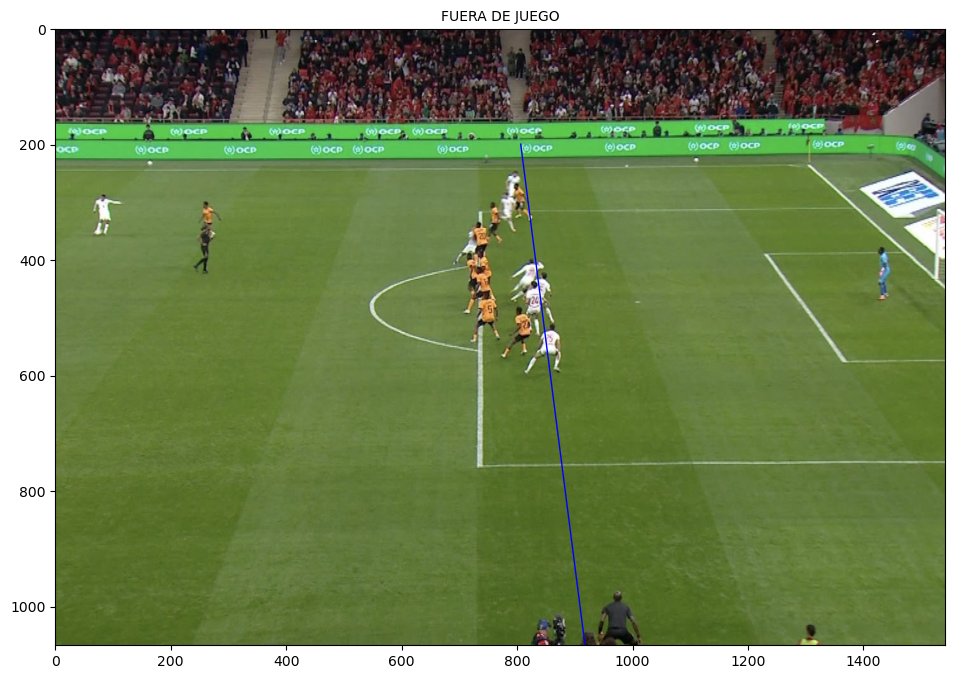

In [21]:
img_fj_bgr = cv2.imread('futbol/test-fuera-de-juego.png')
img_fj_rgb = cv2.cvtColor(img_fj_bgr, cv2.COLOR_BGR2RGB)

u_linea_def, v_linea_def = punto_c(H, U_def)
u_linea_atq, v_linea_atq = punto_c(H, U_atk)

plt.figure(figsize=(12, 8))
plt.imshow(img_fj_rgb)

estado_texto = f"FUERA DE JUEGO" if offside else f"HABILITADO"
plt.title(f"{estado_texto}", fontsize=10)
plt.plot(u_linea_def, v_linea_def, color='blue', linewidth=1)
#para que no se pase la linea
plt.xlim(0, img_fj_rgb.shape[1])
plt.ylim(img_fj_rgb.shape[0], 0)
plt.show()


### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [22]:
#TP/template-alumnos-20261021/salguero/world_img_pts.csv
k_resultante = alc.resolver_ejercicio_5a("salguero/world_img_pts.csv")
print(k_resultante)

[[2794.8  1246.53  325.52]
 [   0.    228.38  213.43]
 [   0.      0.      1.  ]]


In [23]:
r_pose, t_pose = alc.resolver_ejercicio_5b('salguero/gs_10_09_point_correspondences_v5.txt', k_resultante)
print('matriz rotacion:/n', r_pose,'/n', 'matriz traslacion:/n', t_pose)

[Inciso B] Me dieron 50 puntos válidos de 51 y el RMS cerró en 507.1414 px.
matriz rotacion:/n [[ 0.88 -0.14 -0.45]
 [ 0.45 -0.03  0.89]
 [-0.14 -0.99  0.03]] /n matriz traslacion:/n [[ 1.73]
 [-2.25]
 [43.06]]


In [25]:
taxi_matriz = np.array([
    [280.40, 362.10],  # Frame 0
    [317.90, 368.40],  # Frame 5
    [356.50, 375.20],  # Frame 10
    [396.20, 382.60],  # Frame 15
    [437.10, 390.50],  # Frame 20
    [479.30, 399.00],  # Frame 25
    [522.70, 408.10]   # Frame 30
])

camioneta_matriz = np.array([
    [615.20, 220.10],  # Frame 0
    [605.30, 230.90],  # Frame 5
    [594.80, 242.40],  # Frame 10
    [583.60, 254.70],  # Frame 15
    [571.90, 267.50],  # Frame 20
    [559.50, 281.10],  # Frame 25
    [546.40, 295.50],  # Frame 30
])

peatona_matriz = np.array([
    [355.36, 404.64],  # Frame 0
    [370.48, 406.43],  # Frame 5
    [388.15, 408.20],  # Frame 10
    [405.80, 410.05],  # Frame 15
    [424.30, 412.10],  # Frame 20
    [442.90, 414.25],  # Frame 25
    [461.50, 416.40],  # Frame 30
])
print(alc.calcular_velocidad(trayectoria_pixeles, tiempos, matriz_k, rotacion_r, traslacion_t))

NameError: name 'trayectoria_pixeles' is not defined

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

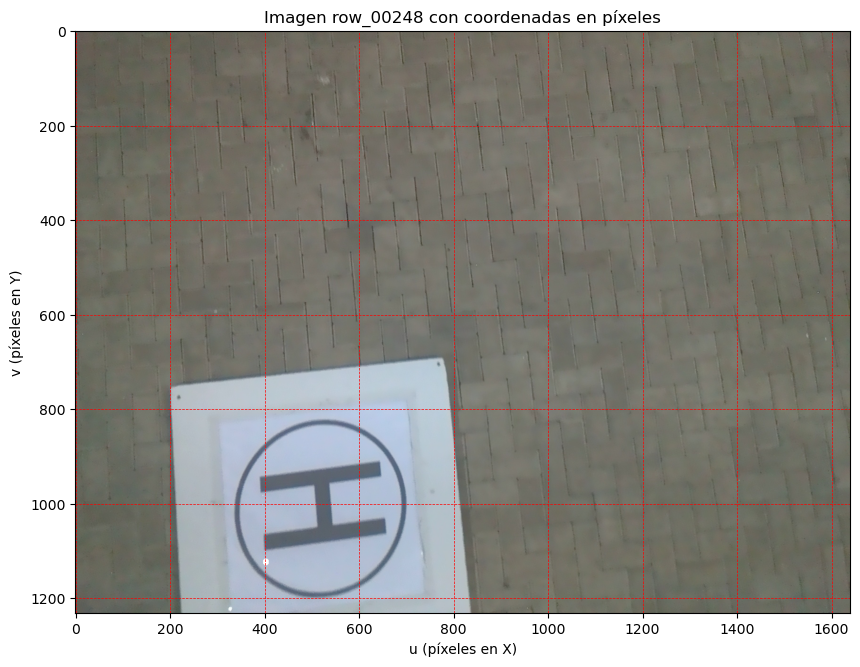

In [26]:
import cv2
import matplotlib.pyplot as plt


# Aca tengo que mirar la foto y decir los pixeles donde estan su centro y esquinas.
# Se grafican los pixeles y a ojo se ve mas o menos donde esta cada punto de interes.
img = cv2.imread('heli/row_00248.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(img_rgb)
plt.grid(True, color='red', linestyle='--', linewidth=0.5)
plt.title('Imagen row_00248 con coordenadas en píxeles')
plt.xlabel('u (píxeles en X)')
plt.ylabel('v (píxeles en Y)')
plt.show()

Proponemos puntos a mano. a)

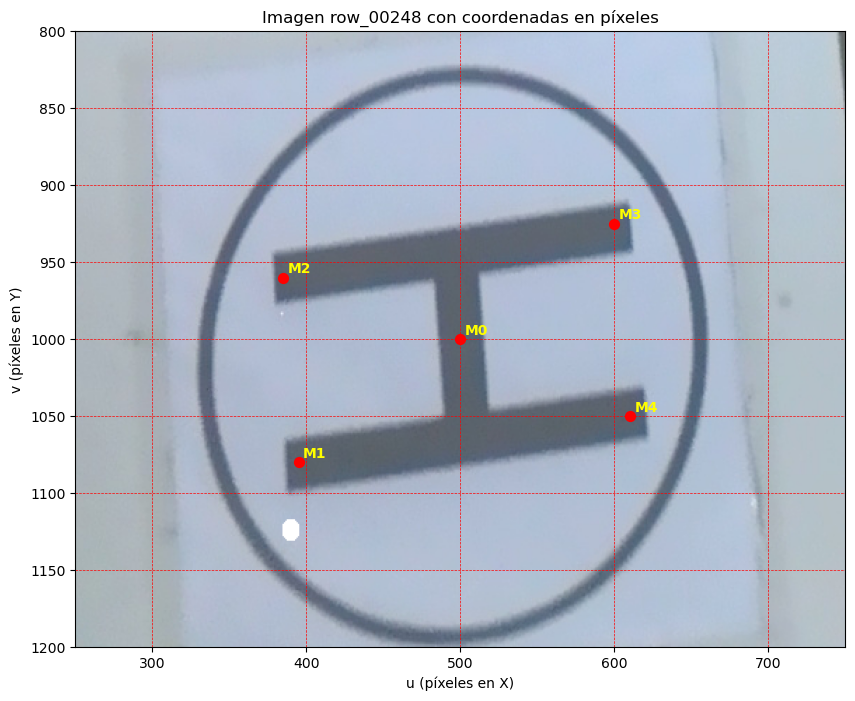

In [27]:
img_vecs = np.array(
    [   [500, 1000],  # M0 (Centro)
        [395, 1080],  # M1 (Sup Izq - cerca del punto blanco)
        [385, 960],  # M2 (Sup Der.)
        [600, 925],  # M3 (Inf Der)
        [610, 1050],  # M4 (Inf Izq)
    ])

plt.figure(figsize=(10, 8))
plt.imshow(img_rgb[800:1200, 250:800],extent=[250,750,1200,800])

etiquetas = ['M0', 'M1', 'M2', 'M3', 'M4']

for i in range(len(img_vecs)):
  u, v = img_vecs[i]
  plt.scatter(u, v, color='red', s=50)
  plt.text(u + 3, v - 3, etiquetas[i], color='yellow', fontweight='bold')

plt.grid(True, color='red', linestyle='--', linewidth=0.5)
plt.title('Imagen row_00248 con coordenadas en píxeles')
plt.xlabel('u (píxeles en X)')
plt.ylabel('v (píxeles en Y)')
plt.show()

In [28]:
# Aca leo los archivos de texto.
K6 = np.loadtxt('heli/K.csv',delimiter=';')
obj_vecs6 = np.loadtxt('heli/object_points.csv', delimiter=';', skiprows=1, usecols=(1, 2, 3))
# Pagina 20 del TP, si las coordenadas no estan centradas debe reemplazarse xi <-- ui - cu , yi <-- vi - cv
cu = K6[0,2] # 819.5
cv = K6[1,2] # 615.5
x_img = img_vecs[:,0] - cu
y_img = img_vecs[:,1] - cv

A = obj_vecs6[1:, :2] - obj_vecs6[0, :2]
Apinv = alc.pseudoinversa(A)

eps = np.zeros(4)

x0 = x_img[0] # centro de la H
y0 = y_img[0] # centro de la H

# Estas son las 4 esquinas de la H, M1 a M4
x_ext = x_img[1:]
y_ext = y_img[1:]

# Armo bu y bv
bu = x_ext * (1+eps) - x0
bv = y_ext * (1+eps) - y0

# calculo I0, J0 multiplicando bu,bv por A
I02D = alc.multMat(Apinv,bu).reshape(-1) # [I0x,I0y]
J02D = alc.multMat(Apinv,bv).reshape(-1) # [J0x,J0y]

# extiendo a 3D agregando z=0
I0 = np.array([I02D[0],I02D[1],0])
J0 = np.array([J02D[0],J02D[1],0])


# Nota: esto es medio a modo de prueba para ver que devuelven las funciones, pues en realidad en mi ultima funcion aplicarPOSIT se hace esto de nuevo adentro de ella.

In [29]:
l1,l2,mu1,mu2 = alc.calculoLambdaMu(I0,J0)

print(f"l1:   {l1}")
print(f"l2:   {l2}")
print(f"mu1:   {mu1}")
print(f"mu2:   {mu2}")

l1:   83.19703301305876
l2:   -83.19703301305876
mu1:   113.10166648468343
mu2:   -113.10166648468343


In [30]:
# I0 J0 no tienen ni profundidad/inclinacion entonces poniendole el l1,mu1 los puedo convertir en vectores 3D
Is = np.array([I0[0], I0[1], l1])
Js = np.array([J0[0], J0[1], mu1])

Is2 = np.array([I0[0], I0[1], l2], dtype=np.float64)
Js2 = np.array([J0[0], J0[1], mu2], dtype=np.float64)

fx = K6[0,0] # distancia focal en X me la dan en K
m0 = np.array([x0,y0]) # centro de la H respecto al centro optico
M0 = obj_vecs6[0] # coordenada 3D real del centro de H

In [31]:
# Si Z0 da negativo (objeto detras de la camara), elegir el segundo par l2,mu2

Rposit,tposit,Z0posit = alc.calcularSalidaPOSIT(Is,Js,fx,m0,M0)
Rposit2, tposit2, Z0posit2 = alc.calcularSalidaPOSIT(Is2, Js2, fx, m0, M0)
np.set_printoptions(precision=3, suppress=True, linewidth=200)

print(f"R: {Rposit}")
print(f"t: {tposit}")
print(f"Z0: {Z0posit}")


R: [[-0.077 -0.971  0.225]
 [-0.941  0.146  0.304]
 [-0.328 -0.189 -0.926]]
t: [[-0.863]
 [ 1.038]
 [ 5.111]]
Z0: 5.110695120852773


In [32]:
# Para las dos poses anteriores calculamos cuantas proyecciones validas tienen y el error medio (siendo validas si Z0>0)
validos1,rms1 = alc.evaluarPose(Rposit,tposit,obj_vecs6,img_vecs,K6)
validos2,rms2 = alc.evaluarPose(Rposit2,tposit2,obj_vecs6,img_vecs,K6)

print(validos1,rms1)
print(validos2,rms2)
#nos dieron 5 validas y teniamos 5 puntos (las 4 esquinas y el centro de H)

5 7.690803133528182
5 8.009703821604974


In [33]:
R,t = alc.aplicarPOSIT(obj_vecs6,img_vecs,K6,MaxIt=20,atol=1e-4)
print(f"R que mejor representa:\n {R}")
print(f"t que mejor representa:\n{t}")
# Esta funcion usa todas las anteriores, proyectamos los puntos de obj_vecs de ambas poses de la camara y calculamos su error comparando con los puntos
# que vimos en a), vamos viendo cual tiene mas puntos validos, y si ambas tienen comparamos su RMS
# en cada iteracion se van ajustando los puntos, y si vemos que la mejoria del error entre una iteracion y otra es minima (RMSprevio - RMS actual)<atol frenamos el algoritmo

R que mejor representa:
 [[-0.063 -0.947  0.314]
 [-0.994  0.089  0.068]
 [-0.093 -0.308 -0.947]]
t que mejor representa:
[[-0.889]
 [ 1.07 ]
 [ 5.27 ]]


La gracia de este punto es que nosotros teniamos nuestros puntos sacados a mano, y los puntos en la vida real, e

#Para el ultimo punto me dicen que como deberia ser R para que este justo encima de la H y que la camara la vea en vertical, osea que el punto quede para arriba.
# Lo cual es rotar la matriz 90 grados hacia la derecha
$$R_{\text{objetivo}} = \begin{bmatrix} \cos(90^\circ) & -\sin(90^\circ) & 0 \\ \sin(90^\circ) & \cos(90^\circ) & 0 \\ 0 & 0 & 1 \end{bmatrix} = \begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

# Y para que se vea en vertical mi t deberia ser que no haya traslacion
$$t_{\text{objetivo}} = \begin{bmatrix} 0 \\ 0 \\ Z_0 \end{bmatrix}$$

# Z0 no importa en este caso pues es la profundidad, viendose mas lejos o mas cerca no cambia lo que me pedian en el ejercicio

---